# Análise de sentimento em português com BERTimbau


Baseado no notebook da aula `05_BERT.ipynb` (BERT no IMDB), adaptado para classificar resenhas em português como positivas ou negativas.

*(escrever: objetivo do trabalho e o que mudou em relação ao notebook da aula)*

## Instruções

Treinar e medir o desempenho do BERTimbau (`neuralmind/bert-base-portuguese-cased`) para classificação binária no dataset `jvanz/portuguese_sentiment_analysis` (20k/5k/5k amostras de treino/validação/teste).

Assim como na aula:
- Implementar o próprio laço de treinamento.
- Verificar overfit em um batch.
- Implementar o acúmulo de gradiente.

Para rodar: Ambiente de execução → Alterar o tipo de ambiente de execução → GPU, e depois Executar tudo.

# Instalação e versões

In [ ]:
!pip install -q datasets

In [ ]:
import importlib.metadata as md_versoes
import platform

versoes = {'python': platform.python_version()}
for pacote in ['torch', 'transformers', 'datasets', 'scikit-learn', 'scipy', 'pandas', 'numpy']:
    try:
        versoes[pacote] = md_versoes.version(pacote)
    except md_versoes.PackageNotFoundError:
        versoes[pacote] = '-'
print(versoes)

{'python': '3.13.16', 'torch': '2.14.1+cu130', 'transformers': '5.22.1', 'datasets': '4.8.5', 'scikit-learn': '1.6.1', 'scipy': '1.16.3', 'pandas': '2.2.3', 'numpy': '2.4.6'}


# Fixando a seed

In [ ]:
import json
import math
import os
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from datasets import load_dataset
from scipy.stats import binomtest
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix, f1_score
from torch import nn
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from transformers import AutoTokenizer, BertModel, get_linear_schedule_with_warmup

In [ ]:
if torch.cuda.is_available():
   dev = "cuda:0"
   print(torch.cuda.get_device_name(dev))
else:
   dev = "cpu"
print(dev)
device = torch.device(dev)
nome_gpu = torch.cuda.get_device_name(dev) if device.type == 'cuda' else 'CPU'

Tesla T4
cuda:0


In [ ]:
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

## Pasta para salvar os resultados

In [ ]:
try:
    from google.colab import drive
    drive.mount('/content/drive')
    PASTA = '/content/drive/MyDrive/sentimento_bertimbau'
except ImportError:
    PASTA = './sentimento_bertimbau'

os.makedirs(PASTA, exist_ok=True)
with open(os.path.join(PASTA, 'versoes.txt'), 'w') as f:
    for pacote, versao in versoes.items():
        f.write(f'{pacote}=={versao}\n')
print('Pasta:', PASTA)

Mounted at /content/drive
Pasta: /content/drive/MyDrive/sentimento_bertimbau


## Preparando Dados

Primeiro, carregamos o dataset do Hugging Face:

In [ ]:
raw = load_dataset('jvanz/portuguese_sentiment_analysis')
print(raw)

README.md:   0%|          | 0.00/162 [00:00<?, ?B/s]

Repo card metadata block was not found. Setting CardData to empty.


dataset_infos.json:   0%|          | 0.00/1.03k [00:00<?, ?B/s]

data/train-00000-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  183MB            

data/train-00000-of-00002.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00002.parquet: reconstructing file:   0%|          |  0.00B /  182MB            

... (5 outputs left out)

Generating train split:   0%|          | 0/1789621 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/149136 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/447405 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['polarity', 'review_text', 'review_text_processed'],
        num_rows: 1789621
    })
    validation: Dataset({
        features: ['polarity', 'review_text', 'review_text_processed'],
        num_rows: 149136
    })
    test: Dataset({
        features: ['polarity', 'review_text', 'review_text_processed'],
        num_rows: 447405
    })
})


## Carregando o dataset

Diferente do IMDB da aula, aqui o dataset já vem com treino, validação e teste. Sorteamos 20k exemplos de treino, 5k de validação e 5k de teste.

*(escrever: como foi feita a limpeza: textos vazios, duplicados e textos que aparecem em mais de um conjunto)*

In [ ]:
max_train = 20000
max_valid = 5000
max_test = 5000


def pegar_amostra(split, size, excluir=frozenset()):
    embaralhado = split.shuffle(seed=SEED)
    # pega uma folga a mais porque a limpeza descarta exemplos
    for fator in (1.5, 3, 6, 12):
        total = min(int(size * fator), len(embaralhado))
        sorteados = embaralhado.select(range(total))
        frame = pd.DataFrame({
            'texto': sorteados['review_text'],
            'rotulo': [int(p) for p in sorteados['polarity']],
        })
        frame['texto'] = frame['texto'].fillna('').astype(str).str.strip()
        frame = frame[frame['texto'].str.len() > 0]
        frame = frame.drop_duplicates('texto')
        frame = frame[~frame['texto'].isin(excluir)]
        if len(frame) >= size or total == len(embaralhado):
            break
    assert len(frame) >= size, 'amostra ficou pequena depois da limpeza'
    return frame.head(size).reset_index(drop=True)


treino = pegar_amostra(raw['train'], max_train)
validacao = pegar_amostra(raw['validation'], max_valid, excluir=set(treino['texto']))
teste = pegar_amostra(raw['test'], max_test, excluir=set(treino['texto']) | set(validacao['texto']))

# checa se não sobrou texto repetido entre os conjuntos
assert not set(treino['texto']) & set(validacao['texto'])
assert not (set(treino['texto']) | set(validacao['texto'])) & set(teste['texto'])

x_train, y_train = treino['texto'].tolist(), treino['rotulo'].tolist()
x_valid, y_valid = validacao['texto'].tolist(), validacao['rotulo'].tolist()
x_test, y_test = teste['texto'].tolist(), teste['rotulo'].tolist()

print(len(x_train), 'amostras de treino.')
print(len(x_valid), 'amostras de desenvolvimento.')
print(len(x_test), 'amostras de teste.')

for nome, frame in [('treino', treino), ('validação', validacao), ('teste', teste)]:
    positivos = int(frame['rotulo'].sum())
    print(f'{nome}: {positivos} positivos ({positivos / len(frame):.1%}), {len(frame) - positivos} negativos')

print('\n3 primeiras amostras treino:')
for x, y in zip(x_train[:3], y_train[:3]):
    print(y, x[:100])

print('\n3 primeiras amostras validação:')
for x, y in zip(x_valid[:3], y_valid[:3]):
    print(y, x[:100])

20000 amostras de treino.
5000 amostras de desenvolvimento.
5000 amostras de teste.
treino: 16302 positivos (81.5%), 3698 negativos
validação: 4070 positivos (81.4%), 930 negativos
teste: 4087 positivos (81.7%), 913 negativos

3 primeiras amostras treino:
1 Testei vários apps gratuitos, mas esse foi o único que atendeu minhas necessidades devido a variedad
1 Na próxima atualização, coloqueem statuss!!
0 Os primeiros 90 minutos são legais. O resto é sobre como me entediar. (Assisti em 3x)

3 primeiras amostras validação:
1 É simplesmente lindo.
1 roteiro e atuações fantásticos.
1 Muito bom. Me ajuda a companhia ativos financeiros e notícias.


*(escrever: comentar a proporção de positivos e negativos (no IMDB era 50/50) e o que isso muda na avaliação)*

## Carregando BERTimbau e visualizando as transformações

In [ ]:
model_name = 'neuralmind/bert-base-portuguese-cased'

tokenizer = AutoTokenizer.from_pretrained(model_name)
encoded_input = tokenizer("Olá, eu sou uma frase só!")
print(encoded_input)
print("Decoding sentence: ", tokenizer.decode(encoded_input["input_ids"]))

config.json:   0%|          | 0.00/647 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/43.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/210k [00:00<?, ?B/s]

added_tokens.json:   0%|          | 0.00/2.00 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

{'input_ids': [101, 1651, 22303, 117, 2779, 7206, 230, 8422, 1203, 106, 102], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}
Decoding sentence:  [CLS] Olá, eu sou uma frase só! [SEP]


Na aula usamos `padding="max_length"` com 512 tokens. As resenhas aqui são bem mais curtas que as do IMDB, então medimos o tamanho em tokens e usamos o percentil 95 como `max_length`.

*(escrever: comentar o histograma e a escolha do max_length)*

Tokens por texto - mediana: 22 | p95: 138 | máximo: 1189
max_length: 144 (4.6% dos textos são cortados)


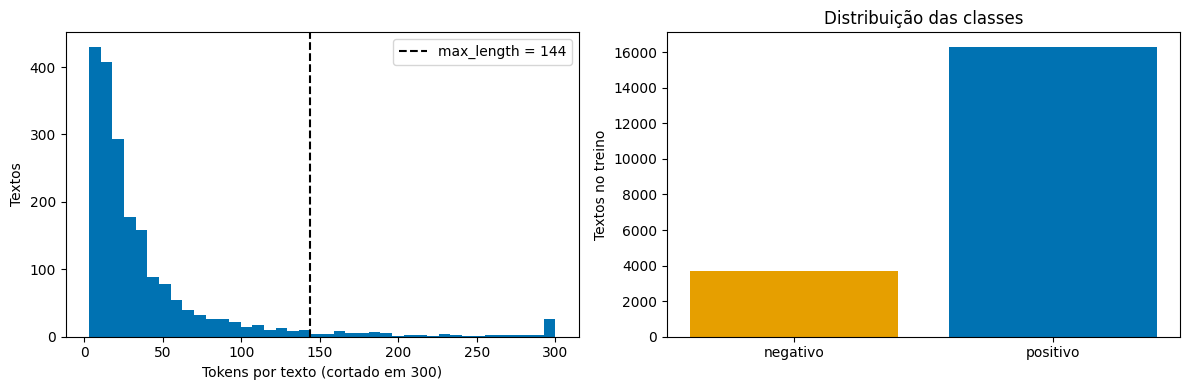

In [ ]:
amostra = treino.sample(min(2000, len(treino)), random_state=SEED)
comprimentos = np.array([len(ids) for ids in tokenizer(amostra['texto'].tolist(), truncation=False)['input_ids']])

p95 = int(np.percentile(comprimentos, 95))
max_length = int(min(512, int(np.ceil(p95 / 16) * 16)))
fracao_cortada = float((comprimentos > max_length).mean())

print('Tokens por texto - mediana:', int(np.median(comprimentos)), '| p95:', p95, '| máximo:', int(comprimentos.max()))
print(f'max_length: {max_length} ({fracao_cortada:.1%} dos textos são cortados)')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(np.clip(comprimentos, 0, 300), bins=40, color='#0072B2')
axes[0].axvline(max_length, color='black', linestyle='--', label=f'max_length = {max_length}')
axes[0].set_xlabel('Tokens por texto (cortado em 300)')
axes[0].set_ylabel('Textos')
axes[0].legend()

contagem = treino['rotulo'].map({0: 'negativo', 1: 'positivo'}).value_counts().reindex(['negativo', 'positivo'])
axes[1].bar(contagem.index, contagem.values, color=['#E69F00', '#0072B2'])
axes[1].set_ylabel('Textos no treino')
axes[1].set_title('Distribuição das classes')
plt.tight_layout()
plt.savefig(os.path.join(PASTA, 'distribuicao_dos_dados.png'), dpi=150)
plt.show()

## Definindo Dataset e Dataloader

In [ ]:
# mesma ideia do IMDBDataset da aula: tokeniza tudo no início e devolve (ids, máscara, rótulo)

class ResenhasDataset(torch.utils.data.Dataset):
    def __init__(self, sentences,
                 labels,
                 model_tokens=model_name,
                 max_length=max_length):
        super().__init__()

        self.tokenizer = AutoTokenizer.from_pretrained(model_tokens)

        encoded = self.tokenizer(sentences,
                                 padding="max_length",
                                 truncation=True,
                                 max_length=max_length)
        self.tokens = encoded["input_ids"]
        self.mask_attention = encoded["attention_mask"]
        self.labels = labels

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
      # indexs, masked_indexs, label
      return torch.tensor(self.tokens[idx]).long(),\
             torch.tensor(self.mask_attention[idx]).long(),\
             torch.tensor(self.labels[idx]).long()

## Modelo de classificação de reviews

*(escrever: arquitetura: BERTimbau + dropout + camada linear em cima do pooler_output)*

In [ ]:
class BertClassifier(nn.Module):
    def __init__(self, num_class, model_name=model_name, dropout=0.1):
        super().__init__()
        self.bert = BertModel.from_pretrained(model_name)
        self.dropout = nn.Dropout(dropout)
        self.classifier = nn.Linear(self.bert.config.hidden_size, num_class)

    def forward(self, input_ids, attention_mask):
        pooled = self.bert(input_ids=input_ids, attention_mask=attention_mask).pooler_output
        return self.classifier(self.dropout(pooled))

## Laço de Treinamento

*(escrever: como funciona o acúmulo de gradiente, o AdamW, o warmup e o clipping)*

In [ ]:
use_bf16 = device.type == 'cuda' and torch.cuda.get_device_capability(device)[0] >= 8
print('Usando bfloat16:', use_bf16)


def forward_batch(model, batch):
    input_ids, attention_mask, labels = (tensor.to(device) for tensor in batch)
    with torch.autocast(device_type=device.type, dtype=torch.bfloat16, enabled=use_bf16):
        logits = model(input_ids, attention_mask)
    loss = F.cross_entropy(logits.float(), labels)
    return loss, logits, labels


def build_optimizer_and_scheduler(model, lr, loader, accum_steps, max_epochs, weight_decay=0.01, warmup_ratio=0.1):
    no_decay = ['bias', 'LayerNorm.weight']
    grouped_parameters = [
        {
            'params': [p for n, p in model.named_parameters() if not any(nd in n for nd in no_decay)],
            'weight_decay': weight_decay,
        },
        {
            'params': [p for n, p in model.named_parameters() if any(nd in n for nd in no_decay)],
            'weight_decay': 0.0,
        },
    ]
    optimizer = torch.optim.AdamW(grouped_parameters, lr=lr)
    total_steps = math.ceil(len(loader) / accum_steps) * max_epochs
    scheduler = get_linear_schedule_with_warmup(
        optimizer, num_warmup_steps=int(warmup_ratio * total_steps), num_training_steps=total_steps
    )
    return optimizer, scheduler


def train_epoch(model, loader, optimizer, scheduler, accum_steps, max_grad_norm=1.0):
    model.train()
    optimizer.zero_grad(set_to_none=True)

    num_batches = len(loader)
    remainder = num_batches % accum_steps or accum_steps
    last_group_start = num_batches - remainder

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    progress_bar = tqdm(loader, leave=False)
    for step, batch in enumerate(progress_bar):
        group_size = accum_steps if step < last_group_start else remainder

        loss, logits, labels = forward_batch(model, batch)
        (loss / group_size).backward()

        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=-1) == labels).sum().item()
        total_samples += labels.size(0)

        if (step + 1) % accum_steps == 0 or (step + 1) == num_batches:
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_grad_norm)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            progress_bar.set_postfix(loss=total_loss / total_samples, acc=total_correct / total_samples)

    return total_loss / total_samples, total_correct / total_samples


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    for batch in tqdm(loader, leave=False):
        loss, logits, labels = forward_batch(model, batch)
        total_loss += loss.item() * labels.size(0)
        total_correct += (logits.argmax(dim=-1) == labels).sum().item()
        total_samples += labels.size(0)

    return total_loss / total_samples, total_correct / total_samples


# novo em relação à aula: probabilidade de positivo para cada exemplo (para F1, limiar e análise de erros)
@torch.no_grad()
def predict_proba(model, loader):
    model.eval()
    probs = []
    for batch in tqdm(loader, leave=False):
        _, logits, _ = forward_batch(model, batch)
        probs.append(torch.softmax(logits.float(), dim=-1)[:, 1].cpu().numpy())
    return np.concatenate(probs)

Usando bfloat16: False


## Overfitting

Verifique o overfit em um batch

In [ ]:
lr = 1e-4#@param {type: "number"}
bs = 5#@param {type: "integer"}
bs_acc_step = 2
max_epochs = 7#@param {type: "integer"}
num_class = 2#@param {type: "integer"}

params = {
    'lr': lr,
    'bs': bs,
    'max_epochs': max_epochs,
    'num_class': num_class,
    'bs_acc_step': bs_acc_step
}

In [ ]:
# Datasets
train_dataset = ResenhasDataset(x_train[:100], y_train[:100])

# Dataloaders
loader_train = DataLoader(train_dataset, batch_size=params['bs'], shuffle=True)

In [ ]:
x_train_, x_train_mask, y_train_ = next(iter(DataLoader(train_dataset, batch_size=5)))
print("\nDimensões dos dados de um minibatch:", x_train_.size())
print("\nDimensões dos dados de um minibatch:", y_train_.size())


Dimensões dos dados de um minibatch: torch.Size([5, 144])

Dimensões dos dados de um minibatch: torch.Size([5])


In [ ]:
### Treino do overfitting

overfit_model = BertClassifier(params['num_class']).to(device)
overfit_optimizer = torch.optim.AdamW(overfit_model.parameters(), lr=params['lr'])
overfit_batch = (x_train_, x_train_mask, y_train_)

overfit_model.train()
for step in range(1, 51):
    overfit_optimizer.zero_grad(set_to_none=True)
    loss, logits, labels = forward_batch(overfit_model, overfit_batch)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(overfit_model.parameters(), 1.0)
    overfit_optimizer.step()

    accuracy = (logits.argmax(dim=-1) == labels).float().mean().item()
    if step % 5 == 0:
        print(f'Passo {step:02d} - loss: {loss.item():.4f} | acurácia: {accuracy:.2f}')

overfit_loss_final, overfit_acc_final = loss.item(), accuracy

del overfit_model, overfit_optimizer
if device.type == 'cuda':
    torch.cuda.empty_cache()

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  438MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Passo 05 - loss: 0.1825 | acurácia: 1.00
Passo 10 - loss: 0.0065 | acurácia: 1.00
Passo 15 - loss: 0.0010 | acurácia: 1.00
Passo 20 - loss: 0.0004 | acurácia: 1.00
Passo 25 - loss: 0.0002 | acurácia: 1.00
Passo 30 - loss: 0.0001 | acurácia: 1.00
Passo 35 - loss: 0.0001 | acurácia: 1.00
Passo 40 - loss: 0.0001 | acurácia: 1.00
Passo 45 - loss: 0.0001 | acurácia: 1.00
Passo 50 - loss: 0.0000 | acurácia: 1.00


*(escrever: comentar o resultado do overfit: a loss vai a quase zero, então o modelo e o laço conseguem aprender)*

## Treinamento - BERTimbau

*(escrever: hiperparâmetros escolhidos e diferenças em relação à aula (lr, batch, épocas, max_length))*

In [ ]:
lr = 3e-5#@param {type: "number"}
bs = 16#@param {type: "integer"}
bs_acc_step = 2
max_epochs = 3#@param {type: "integer"}
num_class = 2#@param {type: "integer"}

params = {
    'lr': lr,
    'bs': bs,
    'max_epochs': max_epochs,
    'num_class': num_class,
    'bs_acc_step': bs_acc_step
}
print('batch efetivo:', params['bs'] * params['bs_acc_step'])

batch efetivo: 32


In [ ]:
# Datasets
train_dataset = ResenhasDataset(x_train, y_train)
val_dataset = ResenhasDataset(x_valid, y_valid)
test_dataset = ResenhasDataset(x_test, y_test)

# Dataloaders
# validação e teste sem shuffle, para as probabilidades ficarem na mesma ordem dos textos
loader_train = DataLoader(train_dataset, batch_size=params['bs'], shuffle=True,
                          generator=torch.Generator().manual_seed(SEED))
loader_val = DataLoader(val_dataset, batch_size=params['bs'] * 2, shuffle=False)
loader_test = DataLoader(test_dataset, batch_size=params['bs'] * 2, shuffle=False)

In [ ]:
x_train_, x_train_mask, y_train_ = next(iter(DataLoader(train_dataset, batch_size=5)))
print("\nDimensões dos dados de um minibatch:", x_train_.size())
print("\nDimensões dos dados de um minibatch:", y_train_.size())


Dimensões dos dados de um minibatch: torch.Size([5, 144])

Dimensões dos dados de um minibatch: torch.Size([5])


In [ ]:
### Treino completo
# diferença em relação à aula: o melhor modelo é escolhido pelo F1 macro da validação, não pela acurácia

CAMINHO_MODELO = os.path.join(PASTA, 'best_bertimbau.pt')

model = BertClassifier(params['num_class']).to(device)
optimizer, scheduler = build_optimizer_and_scheduler(
    model, params['lr'], loader_train, params['bs_acc_step'], params['max_epochs']
)

best_val_f1 = -1.0
best_epoch = None
history = []
inicio = time.time()

for epoch in range(1, params['max_epochs'] + 1):
    train_loss, train_accuracy = train_epoch(
        model, loader_train, optimizer, scheduler, params['bs_acc_step']
    )
    val_loss, val_accuracy = evaluate(model, loader_val)
    val_f1 = f1_score(y_valid, (predict_proba(model, loader_val) >= 0.5).astype(int), average='macro')
    history.append({'epoca': epoch, 'train_loss': train_loss, 'train_acc': train_accuracy,
                    'val_loss': val_loss, 'val_acc': val_accuracy, 'val_f1_macro': val_f1})
    print(
        f'Época {epoch} - '
        f'train_loss: {train_loss:.4f} | train_acc: {train_accuracy:.4f} | '
        f'val_loss: {val_loss:.4f} | val_acc: {val_accuracy:.4f} | val_f1_macro: {val_f1:.4f}'
    )

    if val_f1 > best_val_f1:
        best_val_f1, best_epoch = val_f1, epoch
        torch.save(model.state_dict(), CAMINHO_MODELO)

tempo_treino_min = (time.time() - inicio) / 60
print(f'Melhor F1 macro de validação: {best_val_f1:.4f} (época {best_epoch})')
print(f'Tempo de treino: {tempo_treino_min:.1f} min ({nome_gpu})')

with open(os.path.join(PASTA, 'historico_treino.json'), 'w') as f:
    json.dump(history, f, indent=2)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: neuralmind/bert-base-portuguese-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

Época 1 - train_loss: 0.2754 | train_acc: 0.8806 | val_loss: 0.2116 | val_acc: 0.9240 | val_f1_macro: 0.8630


... (4 outputs left out)

  0%|          | 0/1250 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

  0%|          | 0/157 [00:00<?, ?it/s]

Época 3 - train_loss: 0.0808 | train_acc: 0.9742 | val_loss: 0.3006 | val_acc: 0.9210 | val_f1_macro: 0.8661
Melhor F1 macro de validação: 0.8710 (época 2)
Tempo de treino: 29.3 min (Tesla T4)


 epoca  train_loss  train_acc  val_loss  val_acc  val_f1_macro
     1      0.2754     0.8806    0.2116    0.924        0.8630
     2      0.1500     0.9468    0.2290    0.926        0.8710
     3      0.0808     0.9742    0.3006    0.921        0.8661


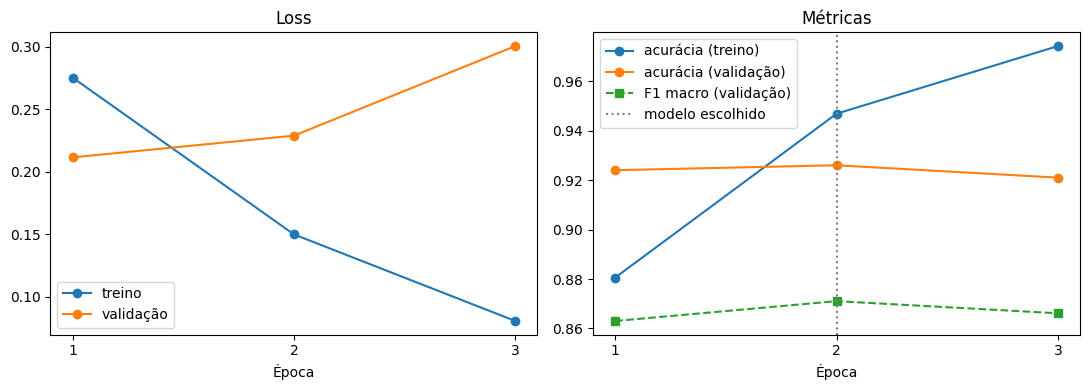

In [ ]:
historico = pd.DataFrame(history)
print(historico.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(historico['epoca'], historico['train_loss'], marker='o', label='treino')
axes[0].plot(historico['epoca'], historico['val_loss'], marker='o', label='validação')
axes[0].set_title('Loss')
axes[0].set_xlabel('Época')
axes[0].legend()
axes[1].plot(historico['epoca'], historico['train_acc'], marker='o', label='acurácia (treino)')
axes[1].plot(historico['epoca'], historico['val_acc'], marker='o', label='acurácia (validação)')
axes[1].plot(historico['epoca'], historico['val_f1_macro'], marker='s', linestyle='--', label='F1 macro (validação)')
axes[1].axvline(best_epoch, color='grey', linestyle=':', label='modelo escolhido')
axes[1].set_title('Métricas')
axes[1].set_xlabel('Época')
axes[1].legend()
for ax in axes:
    ax.set_xticks(historico['epoca'])
plt.tight_layout()
plt.savefig(os.path.join(PASTA, 'curvas_de_treino.png'), dpi=150)
plt.show()

*(escrever: interpretar as curvas: em que época o modelo começa a decorar o treino)*

## Avaliação em teste

In [ ]:
### Avalie seu modelo em teste e retorne a acurácia

model.load_state_dict(torch.load(CAMINHO_MODELO, map_location=device))
test_loss, test_accuracy = evaluate(model, loader_test)
print(f'Teste - loss: {test_loss:.4f} | acurácia: {test_accuracy:.4f}')

  0%|          | 0/157 [00:00<?, ?it/s]

Teste - loss: 0.2289 | acurácia: 0.9272


### Ajuste do limiar de decisão

*(escrever: por que ajustar o limiar na validação em vez de usar 0,5)*

  0%|          | 0/157 [00:00<?, ?it/s]

limiar escolhido: 0.62 | F1 macro validação: 0.8756


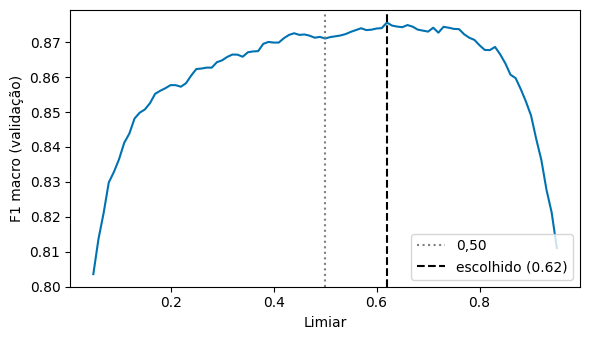

In [ ]:
p_val = predict_proba(model, loader_val)

limiares = np.round(np.arange(0.05, 0.96, 0.01), 2)
f1_por_limiar = [f1_score(y_valid, (p_val >= t).astype(int), average='macro') for t in limiares]
melhor_f1_val = max(f1_por_limiar)
# em caso de empate fica o mais perto de 0.5
empatados = [t for t, f in zip(limiares, f1_por_limiar) if f >= melhor_f1_val - 1e-9]
limiar = float(min(empatados, key=lambda t: abs(t - 0.5)))
print(f'limiar escolhido: {limiar:.2f} | F1 macro validação: {melhor_f1_val:.4f}')

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(limiares, f1_por_limiar, color='#0072B2')
ax.axvline(0.5, color='grey', linestyle=':', label='0,50')
ax.axvline(limiar, color='black', linestyle='--', label=f'escolhido ({limiar:.2f})')
ax.set_xlabel('Limiar')
ax.set_ylabel('F1 macro (validação)')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(PASTA, 'ajuste_do_limiar.png'), dpi=150)
plt.show()

### Resultado no teste

  0%|          | 0/157 [00:00<?, ?it/s]

BERTimbau, limiar 0,50: acurácia 0.9272 | F1 macro 0.8711
BERTimbau, limiar 0.62: acurácia 0.9270 | F1 macro 0.8731

              precision    recall  f1-score   support

    negativo     0.8309    0.7536    0.7904       913
    positivo     0.9461    0.9657    0.9558      4087

    accuracy                         0.9270      5000
   macro avg     0.8885    0.8597    0.8731      5000
weighted avg     0.9250    0.9270    0.9256      5000



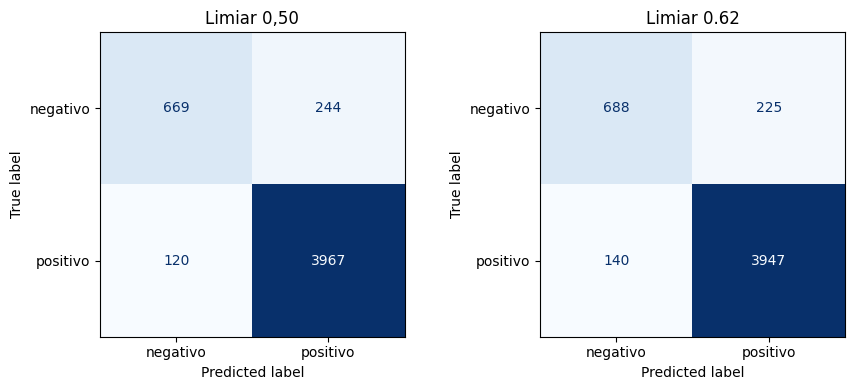

In [ ]:
ROTULOS = ['negativo', 'positivo']
y_teste = np.array(y_test)

teste['p_pos'] = predict_proba(model, loader_test)
teste['previsto_05'] = (teste['p_pos'] >= 0.5).astype(int)
teste['previsto'] = (teste['p_pos'] >= limiar).astype(int)

for nome, coluna in [('limiar 0,50', 'previsto_05'), (f'limiar {limiar:.2f}', 'previsto')]:
    print(f"BERTimbau, {nome}: acurácia {accuracy_score(y_teste, teste[coluna]):.4f} | "
          f"F1 macro {f1_score(y_teste, teste[coluna], average='macro'):.4f}")

acuracia = accuracy_score(y_teste, teste['previsto'])
f1_macro = f1_score(y_teste, teste['previsto'], average='macro')
print()
print(classification_report(y_teste, teste['previsto'], target_names=ROTULOS, digits=4, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, coluna, titulo in [(axes[0], 'previsto_05', 'Limiar 0,50'), (axes[1], 'previsto', f'Limiar {limiar:.2f}')]:
    ConfusionMatrixDisplay.from_predictions(y_teste, teste[coluna], display_labels=ROTULOS,
                                            cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(titulo)
plt.tight_layout()
plt.savefig(os.path.join(PASTA, 'matriz_de_confusao.png'), dpi=150)
plt.show()

### Comparação com baselines

*(escrever: quais baselines foram usados e por quê)*

In [ ]:
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1, 2), sublinear_tf=True)
x_tfidf_treino = tfidf.fit_transform(x_train)
x_tfidf_teste = tfidf.transform(x_test)

baselines = {
    'Classe majoritária': DummyClassifier(strategy='most_frequent'),
    'TF-IDF + reg. logística': LogisticRegression(max_iter=1000),
    'TF-IDF + reg. logística (balanceada)': LogisticRegression(max_iter=1000, class_weight='balanced'),
}
previsoes = {}
for nome, clf in baselines.items():
    clf.fit(x_tfidf_treino, y_train)
    previsoes[nome] = clf.predict(x_tfidf_teste)
previsoes['BERTimbau (limiar 0,50)'] = teste['previsto_05'].to_numpy()
previsoes['BERTimbau (limiar ajustado)'] = teste['previsto'].to_numpy()


def recall_negativo(y, p):
    y, p = np.asarray(y), np.asarray(p)
    return float(((p == 0) & (y == 0)).sum() / (y == 0).sum())


comparacao = pd.DataFrame([
    {'modelo': nome,
     'acurácia': accuracy_score(y_teste, p),
     'F1 macro': f1_score(y_teste, p, average='macro'),
     'recall negativo': recall_negativo(y_teste, p)}
    for nome, p in previsoes.items()
])
print(comparacao.round(4).to_string(index=False))
comparacao.round(4).to_csv(os.path.join(PASTA, 'comparacao_modelos.csv'), index=False)

                              modelo  acurácia  F1 macro  recall negativo
                  Classe majoritária    0.8174    0.4498           0.0000
             TF-IDF + reg. logística    0.8832    0.7560           0.4414
TF-IDF + reg. logística (balanceada)    0.8754    0.8078           0.7733
             BERTimbau (limiar 0,50)    0.9272    0.8711           0.7327
         BERTimbau (limiar ajustado)    0.9270    0.8731           0.7536


### Intervalos de confiança e teste de McNemar

In [ ]:
n_bootstrap = 1000
rng = np.random.default_rng(SEED)
indices_boot = rng.integers(0, len(y_teste), size=(n_bootstrap, len(y_teste)))


def intervalo_bootstrap(previsto):
    accs = np.array([accuracy_score(y_teste[idx], previsto[idx]) for idx in indices_boot])
    f1s = np.array([f1_score(y_teste[idx], previsto[idx], average='macro') for idx in indices_boot])
    return np.percentile(accs, [2.5, 97.5]), np.percentile(f1s, [2.5, 97.5]), f1s


nome_tfidf = max([m for m in previsoes if m.startswith('TF-IDF')],
                 key=lambda m: f1_score(y_teste, previsoes[m], average='macro'))
intervalos, f1s_boot = {}, {}
for nome in ['BERTimbau (limiar ajustado)', nome_tfidf]:
    ic_acc, ic_f1, f1s_boot[nome] = intervalo_bootstrap(previsoes[nome])
    intervalos[nome] = {'acuracia_ic95': ic_acc.tolist(), 'f1_macro_ic95': ic_f1.tolist()}
    print(f'{nome}: acurácia IC95% [{ic_acc[0]:.4f}, {ic_acc[1]:.4f}] | F1 macro IC95% [{ic_f1[0]:.4f}, {ic_f1[1]:.4f}]')

# bootstrap pareado
diferenca = f1s_boot['BERTimbau (limiar ajustado)'] - f1s_boot[nome_tfidf]
ic_diferenca = np.percentile(diferenca, [2.5, 97.5])
print(f'\nganho de F1 macro sobre "{nome_tfidf}": {diferenca.mean():.4f} '
      f'IC95% [{ic_diferenca[0]:.4f}, {ic_diferenca[1]:.4f}]')

# McNemar (exato)
acerta_bert = previsoes['BERTimbau (limiar ajustado)'] == y_teste
acerta_tfidf = previsoes[nome_tfidf] == y_teste
so_bert = int((acerta_bert & ~acerta_tfidf).sum())
so_tfidf = int((~acerta_bert & acerta_tfidf).sum())
p_mcnemar = binomtest(so_bert, so_bert + so_tfidf, 0.5).pvalue if so_bert + so_tfidf > 0 else 1.0
print(f'McNemar: só BERTimbau acertou {so_bert} | só TF-IDF acertou {so_tfidf} | p-valor = {p_mcnemar:.2e}')

BERTimbau (limiar ajustado): acurácia IC95% [0.9194, 0.9340] | F1 macro IC95% [0.8610, 0.8854]
TF-IDF + reg. logística (balanceada): acurácia IC95% [0.8664, 0.8850] | F1 macro IC95% [0.7943, 0.8212]

ganho de F1 macro sobre "TF-IDF + reg. logística (balanceada)": 0.0650 IC95% [0.0515, 0.0781]
McNemar: só BERTimbau acertou 387 | só TF-IDF acertou 129 | p-valor = 5.87e-31


*(escrever: interpretar os intervalos e o p-valor)*

## Análise de erros

In [ ]:
teste['confianca'] = np.where(teste['previsto'] == 1, teste['p_pos'], 1 - teste['p_pos'])
erros = teste[teste['previsto'] != teste['rotulo']].sort_values('confianca', ascending=False)
erros.to_csv(os.path.join(PASTA, 'erros_do_modelo.csv'), index=False)

print(f'{len(erros)} erros em {len(teste)} exemplos ({len(erros) / len(teste):.1%})')
print(f"negativas previstas como positivas: {int((erros['rotulo'] == 0).sum())}")
print(f"positivas previstas como negativas: {int((erros['rotulo'] == 1).sum())}")

for _, linha in erros.head(10).iterrows():
    print(f"\nreal: {ROTULOS[linha['rotulo']]} | previsto: {ROTULOS[linha['previsto']]} | confiança: {linha['confianca']:.2f}")
    print(linha['texto'][:250])

365 erros em 5000 exemplos (7.3%)
negativas previstas como positivas: 225
positivas previstas como negativas: 140

real: negativo | previsto: positivo | confiança: 1.00
foi bom muito bom

real: negativo | previsto: positivo | confiança: 1.00
Super Mega Youh

real: negativo | previsto: positivo | confiança: 1.00
otimo

O que gostei: otima qualidade

O que não gostei: nada a reclamar

real: negativo | previsto: positivo | confiança: 1.00
filme lindo

real: negativo | previsto: positivo | confiança: 1.00
o produto me satifez totalmente

O que não gostei: não há nada de negativo

real: negativo | previsto: positivo | confiança: 1.00
Sandra maravilhosa como sempre!!

real: negativo | previsto: positivo | confiança: 1.00
Muito bom interessante

real: negativo | previsto: positivo | confiança: 1.00
e muito bom eu pensava que era pra fazer montagem nota 10.0000000

real: negativo | previsto: positivo | confiança: 1.00
Ótimas

real: negativo | previsto: positivo | confiança: 1.00
ótima qualidad

*(escrever: comentar os erros mais confiantes)*

#### Anotação manual dos erros

Baixar `erros_para_anotar.csv` da pasta do projeto, preencher a coluna `categoria`, salvar como `erros_anotados.csv` na mesma pasta e rodar a célula seguinte.

Categorias: `rotulo_errado`, `ironia`, `negacao`, `misto`, `ambiguo`, `erro_do_modelo`, `outro`.

In [ ]:
n_erros_anotar = 50
amostra_erros = erros.sample(min(n_erros_anotar, len(erros)), random_state=SEED)
para_anotar = pd.DataFrame({
    'texto': amostra_erros['texto'],
    'rotulo_dataset': amostra_erros['rotulo'].map(dict(enumerate(ROTULOS))),
    'previsto_modelo': amostra_erros['previsto'].map(dict(enumerate(ROTULOS))),
    'confianca': amostra_erros['confianca'].round(3),
    'categoria': '',
})
caminho_para_anotar = os.path.join(PASTA, 'erros_para_anotar.csv')
if not os.path.exists(caminho_para_anotar):  # pra não apagar anotação já feita
    para_anotar.to_csv(caminho_para_anotar, index=False)
    print(len(para_anotar), 'erros salvos em', caminho_para_anotar)
else:
    print(caminho_para_anotar, 'já existe')

/content/drive/MyDrive/sentimento_bertimbau/erros_para_anotar.csv já existe


In [ ]:
caminho_anotado = os.path.join(PASTA, 'erros_anotados.csv')
categorias = ['rotulo_errado', 'ironia', 'negacao', 'misto', 'ambiguo', 'erro_do_modelo', 'outro']
resumo_anotacao = None

if os.path.exists(caminho_anotado):
    anotados = pd.read_csv(caminho_anotado)
    anotados['categoria'] = anotados['categoria'].fillna('').str.strip().str.lower()
    preenchidos = anotados[anotados['categoria'] != '']
    fora_da_lista = sorted(set(preenchidos['categoria']) - set(categorias))
    if fora_da_lista:
        print('categorias fora da lista:', fora_da_lista)

    contagem_cat = preenchidos['categoria'].value_counts().reindex(categorias, fill_value=0)
    resumo_anotacao = (contagem_cat / max(len(preenchidos), 1)).round(3).to_dict()
    print(f'{len(preenchidos)} erros anotados\n')
    print(pd.DataFrame({'erros': contagem_cat,
                        'proporção': (contagem_cat / max(len(preenchidos), 1)).map('{:.0%}'.format)}))

    fig, ax = plt.subplots(figsize=(7, 3.5))
    contagem_cat.sort_values().plot.barh(ax=ax, color='#0072B2')
    ax.set_xlabel('Número de erros')
    ax.set_title('Categorias dos erros (amostra anotada)')
    plt.tight_layout()
    plt.savefig(os.path.join(PASTA, 'categorias_de_erro.png'), dpi=150)
    plt.show()
else:
    print('erros_anotados.csv ainda não existe')

erros_anotados.csv ainda não existe


*(escrever: comentar o resultado da anotação)*

## Testando com frases novas

In [ ]:
def classificar(textos):
    textos = list(textos)
    ds = ResenhasDataset(textos, [0] * len(textos))
    probs = predict_proba(model, DataLoader(ds, batch_size=32))
    return pd.DataFrame({
        'texto': textos,
        'sentimento': [ROTULOS[int(p >= limiar)] for p in probs],
        'prob_positivo': np.round(probs, 4),
    })


exemplos = [
    'Produto excelente, chegou antes do prazo e superou minhas expectativas.',
    'Péssimo, parou de funcionar na primeira semana e ninguém resolve.',
    'O filme é lindo, mas o final deixa a desejar.',
    'Não recomendo, perda de dinheiro.',
    'Adorei o jogo, muito divertido!',
    'Não é ruim, mas também não é nada demais.',
    'Nossa, que maravilha, travou de novo bem na hora que eu mais precisava.',
]

frases = classificar(exemplos)
frases

  0%|          | 0/1 [00:00<?, ?it/s]

,texto,sentimento,prob_positivo
0,"Produto excelente, chegou antes do prazo e sup...",positivo,0.9984
1,"Péssimo, parou de funcionar na primeira semana...",negativo,0.0134
2,"O filme é lindo, mas o final deixa a desejar.",positivo,0.9509
3,"Não recomendo, perda de dinheiro.",negativo,0.0273
4,"Adorei o jogo, muito divertido!",positivo,0.9974
5,"Não é ruim, mas também não é nada demais.",negativo,0.1006
6,"Nossa, que maravilha, travou de novo bem na ho...",positivo,0.9958


*(escrever: comentar as previsões, principalmente nos casos de negação e ironia)*